# Neural additive architectures

**Objective:** compare independent feature networks with shared learned bases,
and distinguish marginal effects from a global contextual contribution.
Prerequisite: [the first additive-model tutorial](01_getting_started.ipynb).
Allow a few minutes on a CPU; the generated execution note records the actual
runtime and tested versions. All reported scores use an untouched test split;
validation rows select the stopping epoch.

## Separate representation from task

For regression, a NAM models $\mu(x)=\beta_0+\sum_j f_j(x_j)$ with one network
per feature. NBM reuses learned basis functions. Both minimize prediction loss,
but sharing changes the representation and regularization. The same wrappers
also support other tasks where declared in the [model chooser](../models/index.rst).

**Execution environment:** nampy 0.3.0, numpy 1.26.4, scikit-learn 1.9.0, torch 2.14.1+cpu, lightning 2.6.6. Python 3.12.13; source revision `638ae3d3aeb991c46a6e144904357977c9c7fcac`; source-content SHA256 `cb792c506d7ebd25c1ad3a6f975f376c8754fee9c0dc514dd085dc0f70fc01ca` (includes local source changes); elapsed 10.3 seconds on this CPU. Runtime varies by hardware.

In [1]:
import logging
import warnings
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message="You called.*self.log.*logger=True.*")
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

rng = np.random.default_rng(7)
X = pd.DataFrame({"x": rng.uniform(-1, 1, 900), "z": rng.uniform(-1, 1, 900)})
y = np.sin(3 * X.x) + 0.7 * X.z**2 + rng.normal(0, 0.15, len(X))
X_fit, X_test, y_fit, y_test = train_test_split(X, y, test_size=0.2, random_state=7)
X_train, X_val, y_train, y_val = train_test_split(X_fit, y_fit, test_size=0.25, random_state=8)
fit_options = dict(max_epochs=100, lr=0.01, batch_size=128, patience=15,
                   random_state=7, logger=False, enable_progress_bar=False,
                   enable_model_summary=False, checkpoint_path=tempfile.mkdtemp())


## Fit independent and shared representations

The simulated response has two known main effects and Gaussian noise. An
interaction model is unnecessary here because the effect of $x$ does not
change with $z$. Fixing the data and evaluation protocol makes the comparison
about representation rather than a different learning problem.

In [2]:
from nampy.models import NAMRegressor, NBMRegressor, NAMformerRegressor

estimators = {
    "NAM": NAMRegressor(layer_sizes=[24, 12], dropout=0., numerical_preprocessing="minmax"),
    "NBM": NBMRegressor(layer_sizes=[16], num_bases=8, nary=[1], dropout=0., bases_dropout=0., numerical_preprocessing="minmax"),
}
rows = []
for name, model in estimators.items():
    model.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
    prediction = model.predict(X_test)
    rows.append({"Model": name, "Test R2": r2_score(y_test, prediction)})
# Parameter counts probe representation size, complementing the comparison tutorial.
for row in rows:
    row["Parameters"] = sum(p.numel() for p in estimators[row["Model"]].model.parameters())
pd.DataFrame(rows)


/home/ad32/projects/package/NAMpy/nampy/models/_base.py:632: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  train_targets=torch.as_tensor(self.data_module.y_train),


,Model,Test R2,Parameters
0,NAM,0.954232,723
1,NBM,0.946015,237


## Read centered effects

Centering transfers the average feature contribution to the intercept. It
preserves prediction while choosing a reference level for the curves.
Compare shape, slope changes, and boundary behavior. A smooth-looking curve
in a sparse region is not strong evidence about that region.
Dashed truth uses the same empirical training-row centering as both fitted
curves. The parameter-count column asks how much representation each fit uses;
it does not rank generalization or stability from a single split.


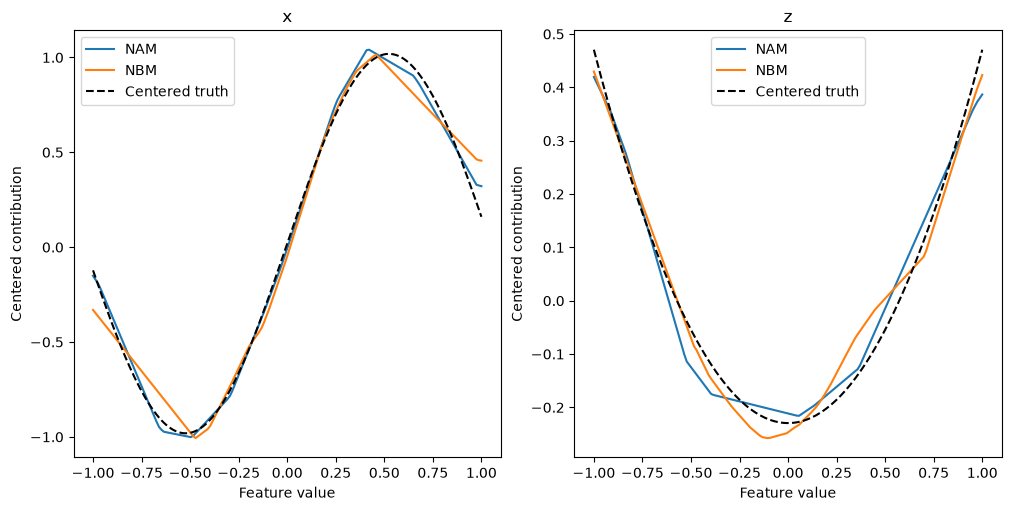

In [3]:
figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for name, model in estimators.items():
    reference = model.predict_components(X_train)
    for axis, feature in zip(axes, X.columns):
        grid = pd.DataFrame({"x": np.zeros(160), "z": np.zeros(160)})
        grid[feature] = np.linspace(-1, 1, 160)
        values = np.asarray(model.predict_components(grid).terms[feature]).reshape(-1)
        values -= np.asarray(reference.terms[feature]).mean()
        axis.plot(grid[feature], values, label=name)
        axis.set(title=feature, xlabel="Feature value", ylabel="Centered contribution")
        axis.set_box_aspect(1)
        axis.legend()
for axis, feature in zip(axes, X.columns):
    values = np.linspace(-1, 1, 160)
    function = (lambda a: np.sin(3*a)) if feature == "x" else (lambda a: .7*a**2)
    axis.plot(values, function(values)-function(X_train[feature].to_numpy()).mean(), "k--", label="Centered truth")
    axis.legend()
plt.show()
plt.close(figure)


## Account for a contextual global term

NAMformer adds a transformer contribution $h(x,z)$ to its marginal heads.
Its full predictor is $\eta=\beta_0+f_x(x)+f_z(z)+h(x,z)$. The
`global_transformer` component must be included to reconstruct the prediction;
it is not a marginal effect of either feature. Reconstruction checks accounting,
while metadata describes dependence. Neither establishes statistical
identifiability or stability.

In [4]:
contextual = NAMformerRegressor(d_model=8, n_heads=2, n_layers=1,
                                  transformer_dim_feedforward=16, head_layer_sizes=(),
                                  attn_dropout=0., numerical_preprocessing="minmax")
contextual.fit(X_train, y_train, X_val=X_val, y_val=y_val, **fit_options)
parts = contextual.predict_components(X_test, center=True, reference_X=X_train)
parts.validate_additive_reconstruction(atol=1e-5)
pd.DataFrame([{"Term": name, "Kind": metadata.kind, "Inputs": ", ".join(metadata.features),
               "Mean absolute contribution": float(np.abs(parts.terms[name]).mean())}
              for name, metadata in parts.term_metadata.items()])


,Term,Kind,Inputs,Mean absolute contribution
0,global_transformer,global,"x, z",0.000940
1,x,main,x,0.506967
2,z,main,z,0.013540


### Does another input change a marginal head?

Hold x fixed while sweeping z over its training range. The x head should stay
constant; a global term is allowed to change. This probes feature dependence
and illustrates the metadata table, while leaving identifiability unresolved.

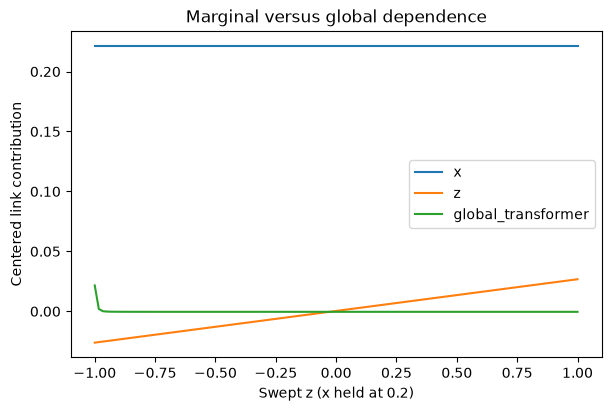

In [5]:
probe = pd.DataFrame({"x": np.full(120, .2), "z": np.linspace(-1, 1, 120)})
probe_parts = contextual.predict_components(probe, center=True, reference_X=X_train)
probe_parts.validate_additive_reconstruction(atol=1e-5)
x_head = np.asarray(probe_parts.terms["x"]).reshape(-1)
assert np.ptp(x_head) < 1e-5
figure, axis = plt.subplots(figsize=(6, 4), constrained_layout=True)
for term in ["x", "z", "global_transformer"]:
    axis.plot(probe.z, np.asarray(probe_parts.terms[term]).reshape(-1), label=term)
axis.set(xlabel="Swept z (x held at 0.2)", ylabel="Centered link contribution", title="Marginal versus global dependence")
axis.legend()
plt.show()
plt.close(figure)

The flat x head agrees with its single-feature contract. Variation of the
global curve is a joint prediction contribution, not a separate marginal
z effect. A successful decomposition does not uniquely identify these pieces.

## Choose additional structure deliberately

Sparse group penalties can suppress whole terms in [SNAM](../models/snam.rst).
[SIAN](../models/sian.rst) searches for interactions; attention and tree models
make different dependence and shape assumptions. [SPAM](../models/spam.rst)
uses polynomial heads: `ranks` sets their structure, while `reg_order` sets a
regularization norm order, not polynomial degree.

The [architecture validation report](../development/notebooks/03_neural_models.ipynb)
executes the broader registry without mixing quantile loss and regression R².
Use [distributional modeling](04_distributional_models.ipynb) when changing the
prediction target matters more than changing its representation.

**Recommended next:** [Distributional models and ensemble uncertainty](04_distributional_models.ipynb).
